## Intallations et importations

In [2]:
from logging import disable, root
!pip -q install spacy nltk pandas
!python -m spacy download fr_core_news_md
!python -m spacy download en_core_web_md


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 MB 24.8 MB/s  0:00:01m0:00:0100:01

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_md')
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 22.8 MB/s  0:00:01 eta 0:00:01

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')


In [79]:
import spacy
import numpy as np
import pandas as pd
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

print("spaCy :", spacy.__version__)


spaCy : 3.8.18


## Chargement des données

In [80]:
chemin_appr_fr = 'data/deft09_parlement_appr.xml/deft09_parlement_appr_fr.xml'
#chemin_test_fr = 'data/deft09_parlement_test.xml/deft09_parlement_test_fr.xml'

## Chargement et extraction des données

In [81]:
def extract_deft_data(xml_link):
    tree = ET.parse(xml_link)
    root = tree.getroot()

    textes = []
    partis = []

    for doc in root.findall('.//doc'):
        noeud_parti = doc.find('.//PARTI')
        noeud_texte = doc.find('.//texte')

        if noeud_parti is not None and noeud_texte is not None:
            parti_val = noeud_parti.get('valeur')
            corpus = " ".join(noeud_texte.itertext()).strip()

            if parti_val and corpus:
                textes.append(corpus)
                partis.append(parti_val.strip())

    return textes, partis

print("Extraction des données en cours ...")
all_text, all_partis = extract_deft_data(chemin_appr_fr)
print(f"Total de documents extraits : {len(all_text)}\n")

Extraction des données en cours ...
Total de documents extraits : 19370



In [32]:
# découpage dynamique des données d'entraînement et de test (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    all_text,
    all_partis,
    test_size=0.2,
    random_state=42,
    stratify=all_partis
)

print(f"Entraînement : {len(X_train)} documents")
print(f"Test         : {len(X_test)} documents\n")

Entraînement : 15496 documents
Test         : 3874 documents



### 1a. Construction du pipeline TF-IDF + SVM et évaluation avec les différentes métriques demandées

In [33]:
# pipeline TF-IDF + SVM
print("Construction et entraînement du pipeline TF-IDF + SVM ...")
pipeline_baseline = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        max_df=0.90,
        min_df=5
    )),
    ('svm', SVC(kernel='linear', random_state=42))
])

pipeline_baseline.fit(X_train, y_train)

# évaluation avec les métriques
print("Génération des prédictions ...\n")
y_pred = pipeline_baseline.predict(X_test)

print("="*50)
print("RÉSULTATS DE LA BASELINE (TF-IDF + SVM)")
print("="*50)
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"F1 Macro : {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1 Micro : {f1_score(y_test, y_pred, average='micro'):.4f}")

print("\n--- Précision et Rappel par classe ---")
print(classification_report(y_test, y_pred))

Construction et entraînement du pipeline TF-IDF + SVM...
Génération des prédictions...

RÉSULTATS DE LA BASELINE (TF-IDF + SVM)
Accuracy : 0.4866
F1 Macro : 0.4134
F1 Micro : 0.4866

--- Précision et Rappel par classe ---
              precision    recall  f1-score   support

        ELDR       0.47      0.14      0.21       402
     GUE-NGL       0.68      0.52      0.59       538
      PPE-DE       0.49      0.72      0.58      1371
         PSE       0.41      0.45      0.43      1088
   Verts-ALE       0.53      0.17      0.25       475

    accuracy                           0.49      3874
   macro avg       0.52      0.40      0.41      3874
weighted avg       0.50      0.49      0.46      3874



Génération de la matrice de confusion visuelle 



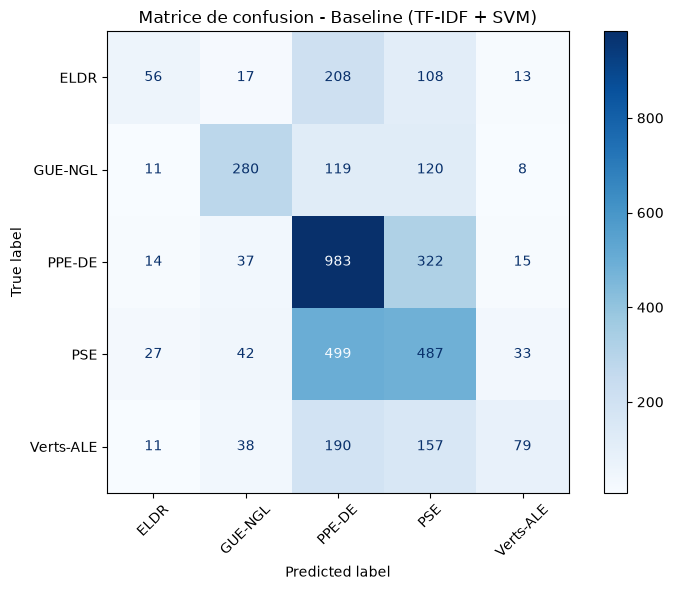

In [39]:
print(f"Génération de la matrice de confusion visuelle \n")

fig, ax = plt.subplots(figsize=(8, 6))

# affichage de la matrice avec un dégradé de bleu
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap=plt.cm.Blues,
    ax=ax,
    xticks_rotation=45 # inclinaison des étiquettes pour une lecture facile
)

plt.title("Matrice de confusion - Baseline (TF-IDF + SVM)")
plt.tight_layout()
plt.show()

### 1b. Analyse des résultats obtenus, notamment à partir de la matrice de confusion et des performances obtenues pour chaque classe

L'analyse de la baseline (représentation TF-IDF associée à un classifieur SVM linéaire) montre que le modèle obtient une exactitude globale (accuracy) de 48,66 %. Bien que ce score soit nettement supérieur à une sélection aléatoire (qui serait de 20 % pour 5 classes équilibrées), il révèle d'importantes disparités de prédiction. Le score F1-macro de 41,34 %, inférieur à l'accuracy, traduit ces déséquilibres et souligne que certaines classes sont beaucoup moins bien reconnues que d'autres.

#### 1. Biais vers la classe majoritaire

L'examen de la matrice de confusion et du rapport de classification met en évidence un biais important du classifieur en faveur de la classe majoritaire, le PPE-DE (1371 documents dans le jeu de test).

Ce parti bénéficie du meilleur rappel (72 %), mais d'une précision moyenne (49 %).

Le modèle a tendance à se rabattre sur l'étiquette `PPE-DE` lorsqu'il est incertain. La matrice montre par exemple que 499 documents du `PSE` et 208 documents de l'ELDR ont été classés à tort dans cette catégorie.

#### 2. Pénalisation des classes minoritaires

Ce comportement statistique pénalise les groupes moins représentés. Les partis comme `ELDR` et les `Verts-ALE` voient la majorité de leurs textes absorbés par les autres classes, ce qui se traduit par des scores de rappel très faibles (respectivement 14 % et 17 %).

#### 3. Spécificité lexicale

A l'inverse, le groupe `GUE-NGL` se distingue avec la meilleure précision du modèle (68 %) et le meilleur score F1 (59 %), et ce malgré un support modéré (538 documents). Cela suggère que les orateurs de ce parti utilisent un vocabulaire politique particulièrement distinct, ce qui permet à l'approche TF-IDF (basée sur la fréquence des mots) de les identifier beaucoup plus efficacement que les autres groupes.

### Question 2 : Synthèse des approches des participants à DEFT 2009

#### 2a. Principe général de l'approche proposée
Lors de la campagne DEFT 2009, la majorité des participants a abordé la tâche d'identification du parti politique en utilisant des méthodes d'apprentissage automatique supervisé classiques, avec une forte prédominance des **Séparateurs à Vaste Marge (SVM)**.

Le principe général reposait sur une représentation vectorielle des discours sous forme de sac de mots (Bag-of-Words), avec une pondération **TF-IDF**. Pour optimiser ces modèles statistiques, les équipes ont massivement eu recours à :
* Utilisation de **n-grammes de mots** et de **n-grammes de caractères**
* Application de **prétraitements linguistiques**

#### 2b. Principales forces et limites dans le contexte de la tâche

**Forces :**
* L'association du TF-IDF et des classifieurs linéaires (comme les SVM) est extrêmement efficace pour traiter les matrices creuses de très grande dimension (vocabulaire riche), typiques de ce genre de corpus.
* Contrairement aux modèles neuronaux modernes, l'approche linéaire permet d'analyser les poids des variables pour identifier explicitement le vocabulaire caractéristique de chaque parti politique.
* L'approche basée sur la fréquence est facilement transposable aux autres langues du corpus.

**Limites :**
* L'approche en sac de mots détruit l'ordre des mots. Le système est incapable de comprendre les relations syntaxiques complexes, la négation ou l'ironie, pourtant fréquentes dans les débats parlementaires.
* Ces algorithmes statistiques ont tendance à maximiser l'exactitude globale (Accuracy) en prédisant souvent la classe majoritaire (ici le PPE-DE), ce qui pénalise fortement la détection des petits partis.
* Le modèle apprend à lier des mots-clés spécifiques à un parti. Si le sujet des débats change (par exemple, si l'on passe de l'agriculture au numérique), les performances du modèle risquent de chuter car, le vocabulaire change, même si l'orateur reste le même.

## 3. Représentation par espaces de thèmes

### 3a. Construisez un premier système LDA + SVM et comparez ses performances au système baseline

In [84]:
# chargement des mots vides français
print("Chargement des mots vides...")
if 'nlp_fr' not in globals():
    nlp_fr = spacy.load("fr_core_news_md")
mots_vides_fr = list(nlp_fr.Defaults.stop_words)

# chargement des mots vides de base
print("Chargement des mots vides standards...")
nlp_fr = spacy.load("fr_core_news_md")
stop_words_spacy_bruts = list(nlp_fr.Defaults.stop_words)

# détection automatique des vocabulaires parasite du domaine
print("Analyse automatique des mots parasites...")
# utilisation d'un découpeur de sklearn pour normaliser la liste
tokernizer_sklearn = CountVectorizer().build_tokenizer()
mots_vides_fr = set()

for mot in stop_words_spacy_bruts:
    tokens = tokernizer_sklearn(mot.lower())
    mots_vides_fr.update(tokens)

mots_vides_fr = list(mots_vides_fr)

#print(f"Nombre de stop words après alignement : {len(mots_vides_fr)}")

# on crée un vectoriseur temporaire avec les mots vides
vect_temp = CountVectorizer(stop_words=mots_vides_fr, lowercase=True)
X_temp = vect_temp.fit_transform(X_train)

# on calcule la fréquence totale de chaque mot
frequences = np.asarray(X_temp.sum(axis=0)).ravel()
mots = vect_temp.get_feature_names_out()

# on associe chaque mot à sa fréquence et on trie
mots_frequences = list(zip(mots, frequences))
mots_frequences = sorted(mots_frequences, key=lambda x: x[1], reverse=True)

# extraction des 30 mots les plus fréquents
top_30_bruit = [mot for mot, freq in mots_frequences[:30]]
print(f"\nMots automatiquement exclus : {top_30_bruit}\n")

# 3. Ajout à la liste finale
mots_vides_fr.extend(top_30_bruit)

Chargement des mots vides...
Chargement des mots vides standards...
Analyse automatique des mots parasites...

Mots automatiquement exclus : ['commission', 'monsieur', 'président', 'européenne', 'pays', 'union', 'rapport', 'parlement', 'été', 'politique', 'états', 'conseil', 'faire', 'bien', 'membres', 'europe', 'européen', 'question', 'devons', 'commissaire', 'non', 'voudrais', 'droits', 'contre', 'faut', 'travail', 'proposition', 'aujourd', 'point', 'sécurité']



In [69]:
# construction du pipeline LDA + SVM
print("Construction et entraînement du pipeline LDA + SVM")

def lda_svm_pipeline(mots_vides_fr, n_components, max_iter, dtp = None, twp = None):

    lda_params = {
        "n_components": n_components,
        "random_state" : 42,
        "max_iter" : max_iter,
    }

    if dtp :
        lda_params["doc_topic_prior"] = dtp

    if twp :
       lda_params["topic_word_prior"] = twp

    return Pipeline([
        # CountVectorizer extrait les fréquences brutes des mots
        ('vect', CountVectorizer(max_df=0.85, min_df=10, stop_words=mots_vides_fr, lowercase=True)),
        # LDA identifie 10 thèmes latents à partir du vocabulaire
        ('lda', LatentDirichletAllocation(**lda_params)),
        # Le SVM classe le document en fonction des proportions des 10 thèmes
        ('svm', SVC(kernel='linear', random_state=42))
    ])

pipeline_response = lda_svm_pipeline(mots_vides_fr, 10, 5, dtp=None, twp=None)

# entraînement sur le jeu de train
pipeline_response.fit(X_train, y_train)

# prédictions sur le jeu de test
print("Génération des prédictions ...\n")
y_pred_lda = pipeline_response.predict(X_test)

# évaluation et comparaison
print("=" * 50)
print("RÉSULTATS DU MODÈLE LDA + SVM")
print("=" * 50)
print(f"Accuracy : {accuracy_score(y_test, y_pred_lda):.4f}")
print(f"F1 Macro : {f1_score(y_test, y_pred_lda, average='macro'):.4f}")
print(f"F1 Micro : {f1_score(y_test, y_pred_lda, average='micro'):.4f}")

print("\n--- Précision et Rappel par classe ---")
print(classification_report(y_test, y_pred_lda, zero_division=0))

Construction et entraînement du pipeline LDA + SVM
Génération des prédictions ...

RÉSULTATS DU MODÈLE LDA + SVM
Accuracy : 0.3539
F1 Macro : 0.1046
F1 Micro : 0.3539

--- Précision et Rappel par classe ---
              precision    recall  f1-score   support

        ELDR       0.00      0.00      0.00       402
     GUE-NGL       0.00      0.00      0.00       538
      PPE-DE       0.35      1.00      0.52      1371
         PSE       0.00      0.00      0.00      1088
   Verts-ALE       0.00      0.00      0.00       475

    accuracy                           0.35      3874
   macro avg       0.07      0.20      0.10      3874
weighted avg       0.13      0.35      0.19      3874



**1. Chute drastique des performances**
Le passage de la représentation TF-IDF (Baseline) à la représentation thématique (LDA) entraîne une forte dégradation des performances :
* **L'Accuracy** chute de 48,66 % à 35,39 %.
* **Le F1-Macro** s'effondre littéralement, passant de 41,34 % à seulement 10,46 %.

**2. Effondrement sur la classe majoritaire**
Le rapport de classification montre que le modèle LDA + SVM est devenu incapable de discriminer les classes. La précision et le rappel sont de 0 pour les partis ELDR, GUE-NGL, PSE et Verts-ALE. Le modèle prédit systématiquement la classe majoritaire (PPE-DE) pour l'intégralité des 3874 documents du jeu de test, ce qui explique pourquoi le rappel du PPE-DE est de 1.00 (100 %) et l'Accuracy globale plafonne à 35 % (qui correspond simplement à la proportion mathématique du PPE-DE dans le jeu de test).

**3. Explication sémantique et limite de l'approche**
Cette perte de pouvoir prédictif s'explique par la nature de l'information extraite :
* **La Baseline (TF-IDF)** conservait des milliers de colonnes représentant des mots spécifiques. Le SVM pouvait s'appuyer sur le vocabulaire idéologique ou rhétorique propre à chaque parti (ce qui fonctionnait très bien pour le GUE-NGL).
* **Le modèle LDA** lisse ces détails lexicaux pour réduire le document à 10 grandes proportions thématiques (ex: % économie, % agriculture, % relations internationales). Or, au Parlement européen, **tous les partis débattent des mêmes thèmes** à l'ordre du jour. Savoir qu'un texte parle d'écologie à 80 % ne suffit pas à savoir si l'orateur est de droite ou de gauche, car le modèle LDA ne capte pas *l'opinion* ou *la polarité* sur ce thème, mais uniquement le sujet de discussion. La représentation thématique seule est donc insuffisante pour cette tâche de classification politique.

### 3b. Expliquez brièvement les principaux hyperparamètres de LDA utilisés dans votre système, notamment :
- n_components : nombre de thèmes ;
- max_iter : nombre maximal d'itérations ;
- doc_topic_prior : paramètre contrôlant la distribution des thèmes dans les documents ;
- topic_word_prior : paramètre contrôlant la distribution des mots dans les thèmes.

*   **`n_components` (nombre de thèmes) :** Définit la quantité de sujets latents ($K$) que l'algorithme doit extraire du corpus. Un nombre trop faible force le modèle à fusionner des concepts distincts (ex: économie et écologie dans le même thème), tandis qu'un nombre trop élevé génère des thèmes redondants ou trop spécifiques (bruités) pour être interprétables.

*   **`max_iter` (nombre maximal d'itérations) :** Détermine le nombre de cycles d'apprentissage que l'algorithme effectue sur les données pour ajuster ses distributions de probabilités avant de s'arrêter. Une valeur plus élevée aide le modèle à atteindre une convergence optimale, mais augmente le temps de calcul.

*   **`doc_topic_prior` (Alpha / $\alpha$) :** Contrôle la distribution des thèmes au sein de chaque document. Une valeur faible force une distribution creuse (sparse) : le modèle considérera qu'un discours ne porte que sur un ou deux thèmes dominants. Une valeur élevée supposera que chaque discours est un mélange très varié de tous les thèmes existants.

*   **`topic_word_prior` (Beta / $\beta$ ou $\eta$) :** Contrôle la distribution des mots au sein de chaque thème. Une valeur faible crée des thèmes extrêmement concentrés autour d'une poignée de mots-clés très spécifiques. Une valeur plus élevée produit des thèmes plus vastes et diffus, utilisant une répartition plus uniforme d'un grand vocabulaire.

*PS :* Dans notre code, nous n'avons pas défini manuellement `doc_topic_prior` et `topic_word_prior`. L'implémentation de Scikit-learn leur attribue donc par défaut la valeur de $1 / n\_components$. Avec nos 10 thèmes, ces deux hyperparamètres ont été fixés automatiquement à $0.1$. Ces valeurs faibles favorisent des documents concentrés sur peu de thèmes et des thèmes concentrés sur un vocabulaire restreint.

### 3c. Faites varier au moins deux hyperparamètres, dont obligatoirement n_components. Utilisez un nombre raisonnable de valeurs et comparez les performances obtenues.
Vous pourrez par exemple étudier l'influence de :
- n_components ;
- doc_topic_prior ;
- topic_word_prior ;
- max_iter.

In [70]:
# initialisation des hyperparamètres à tester
n_components_list = [5, 15, 30]
doc_topic_prior_list = [0.1, 0.8]

print("Début de l'exploration des hyperparamètres \n")

for n_themes in n_components_list:
    for alpha in doc_topic_prior_list:
        hyper_pipeline = lda_svm_pipeline(mots_vides_fr, n_themes, 5, alpha, twp=None)

        hyper_pipeline.fit(X_train, y_train)
        y_pred_hyperPipeline = hyper_pipeline.predict(X_test)

        f1 = f1_score(y_test, y_pred_hyperPipeline, average='macro')
        print(f"n_components = {n_themes:2d} | doc_topic_prior (alpha) = {alpha:.1f} --> F1 Macro : {f1:.4f}")

Début de l'exploration des hyperparamètres 

n_components =  5 | doc_topic_prior (alpha) = 0.1 --> F1 Macro : 0.1046
n_components =  5 | doc_topic_prior (alpha) = 0.8 --> F1 Macro : 0.1046
n_components = 15 | doc_topic_prior (alpha) = 0.1 --> F1 Macro : 0.1046
n_components = 15 | doc_topic_prior (alpha) = 0.8 --> F1 Macro : 0.1046
n_components = 30 | doc_topic_prior (alpha) = 0.1 --> F1 Macro : 0.1570
n_components = 30 | doc_topic_prior (alpha) = 0.8 --> F1 Macro : 0.1506


### 3d. Analyse des résultats et examen des thèmes

#### Analyse des résultats

* **Influence de `n_components` :** Les résultats montrent une stagnation totale du F1-Macro à `0.1046` pour 5 et 15 thèmes. A ce stade, le modèle manque de caractéristiques et continue de prédire systématiquement la classe majoritaire `PPE-DE`. En revanche, le passage à **30 thèmes** permet au F1-Macro de décoller très légèrement (environ 0.15). En augmentant la granularité des thèmes (30 au lieu de 5 ou 10), on offre au SVM un vecteur de caractéristiques un peu plus riche, ce qui lui permet de commencer timidement à distinguer d'autres partis politiques.
Cependant, cela reste très insuffisant par rapport aux performances d'une vectorisation TF-IDF classique.

* **Influence de `doc_topic_prior` ($\alpha$) :** On constate que ce paramètre n'a aucune influence lorsque le nombre de thèmes est trop faible (5 ou 15 thèmes), car le modèle est bloqué sur la classe majoritaire. Pour 30 thèmes, une valeur faible ($\alpha=0.1$) donne de très légers meilleurs résultats (0.1570) qu'une valeur élevée ($\alpha=0.8$, score de 0.1506).

In [73]:
# entraînement du modèle LDA seul pour visualiser les thèmes
vect_visu = CountVectorizer(max_df=0.85, min_df=10, stop_words=mots_vides_fr, lowercase=True)
X_train_vect = vect_visu.fit_transform(X_train)

lda_visu = LatentDirichletAllocation(n_components=15, random_state=42, max_iter=10)
lda_visu.fit(X_train_vect)

mots = vect_visu.get_feature_names_out()

print("--- Top 10 des mots pour chaque thème (Modèle à 15 thèmes) ---\n")
for id, theme in enumerate(lda_visu.components_):
    # récupération des 10 mots avec le poids le plus fort pour un thème X
    indices_mots_forts = theme.argsort()[:-11:-1] # trie des mots du thème selon leur poids
    mots_cles = [mots[i] for i in indices_mots_forts]
    print(f"Thème {id+1:2d} : {' | '.join(mots_cles)}")

--- Top 10 des mots pour chaque thème (Modèle à 15 thèmes) ---

Thème  1 : emploi | entreprises | sociale | économique | travailleurs | marché | régions | aides | économie | secteur
Thème  2 : homme | monde | unis | mort | terrorisme | peine | accord | omc | gouvernement | personnes
Thème  3 : israël | paix | russie | état | accord | palestiniens | vie | orient | retraite | situation
Thème  4 : adhésion | turquie | élargissement | candidats | homme | citoyens | ue | droit | état | gouvernement
Thème  5 : développement | sud | coopération | pauvreté | aide | monde | afrique | pauvres | millions | santé
Thème  6 : droit | justice | citoyens | juridique | état | cas | gouvernement | cour | législation | données
Thème  7 : femmes | personnes | enfants | égalité | hommes | immigration | matière | droit | vie | asile
Thème  8 : pêche | transport | environnement | directive | mesures | transports | secteur | rapporteur | déchets | matière
Thème  9 : produits | animaux | consommateurs | santé 

On peut regrouper ces thèmes en grandes catégories de débats parlementaires :
* **Dossiers économiques et sociaux :** Le Thème 1 (*emploi, entreprises, sociale, marché*) et le Thème 10 (*marché, concurrence, libéralisation, consommateurs*) isolent clairement les débats sur le marché intérieur et le droit du travail.

* **Affaires étrangères et crises internationales :** Les Thèmes 3 (*israël, paix, palestiniens, orient*), 4 (*adhésion, turquie, élargissement*) et 12 (*guerre, irak, armes, résolution*) correspondent à des résolutions spécifiques du Parlement sur des crises géopolitiques majeures de l'époque.

* **Société et droits fondamentaux :** Le Thème 7 (*femmes, enfants, égalité, immigration, asile*) regroupe les questions sociétales.